In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/mariamtrad/salesdata/sales_data.csv


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv("/kaggle/input/datasets/mariamtrad/salesdata/sales_data.csv")
df.head()

,Order_ID,Order_Date,Region,Category,Product,Quantity,Unit_Price,Discount,Sales,Cost,Profit
0,ORD-1001,2025-01-01,North,Office Supplies,Stapler,5,9,0.10,40.5,29.09,11.41
1,ORD-1002,2025-01-03,East,Electronics,Keyboard,2,45,0.10,81.0,46.41,34.59
2,ORD-1003,2025-01-05,South,Clothing,T-Shirt,4,22,0.15,74.8,53.32,21.48
3,ORD-1004,2025-01-07,West,Electronics,Monitor,4,220,0.05,836.0,500.63,335.37
4,ORD-1005,2025-01-09,North,Clothing,T-Shirt,1,22,0.15,18.7,12.92,5.78


In [4]:
df.shape

(180, 11)

In [5]:
df.columns

Index(['Order_ID', 'Order_Date', 'Region', 'Category', 'Product', 'Quantity',
       'Unit_Price', 'Discount', 'Sales', 'Cost', 'Profit'],
      dtype='object')

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 180 entries, 0 to 179
Data columns (total 11 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Order_ID    180 non-null    object 
 1   Order_Date  180 non-null    object 
 2   Region      180 non-null    object 
 3   Category    180 non-null    object 
 4   Product     180 non-null    object 
 5   Quantity    180 non-null    int64  
 6   Unit_Price  180 non-null    int64  
 7   Discount    180 non-null    float64
 8   Sales       180 non-null    float64
 9   Cost        180 non-null    float64
 10  Profit      180 non-null    float64
dtypes: float64(4), int64(2), object(5)
memory usage: 15.6+ KB


In [7]:
df.describe()

,Quantity,Unit_Price,Discount,Sales,Cost,Profit
count,180.000000,180.000000,180.000000,180.000000,180.000000,180.000000
mean,4.061111,148.538889,0.076389,528.844722,352.295167,176.549556
std,1.992062,212.294682,0.054780,814.037555,558.272629,264.688653
min,1.000000,5.000000,0.000000,4.500000,2.550000,1.450000
25%,2.000000,22.000000,0.050000,52.762500,34.537500,17.845000
50%,4.000000,70.000000,0.100000,240.500000,154.310000,81.215000
75%,6.000000,187.500000,0.100000,720.625000,484.375000,227.512500
max,7.000000,850.000000,0.150000,5652.500000,4008.160000,1644.340000


In [8]:
df.isnull().sum()

Order_ID      0
Order_Date    0
Region        0
Category      0
Product       0
Quantity      0
Unit_Price    0
Discount      0
Sales         0
Cost          0
Profit        0
dtype: int64

In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
df["Order_Date"] = pd.to_datetime(df["Order_Date"])

In [11]:
df = df.drop_duplicates()

In [12]:
numeric_cols = ["Quantity", "Unit_Price", "Discount", "Sales", "Cost", "Profit"]

for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

In [13]:
df.info()
df.isnull().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 180 entries, 0 to 179
Data columns (total 11 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   Order_ID    180 non-null    object        
 1   Order_Date  180 non-null    datetime64[ns]
 2   Region      180 non-null    object        
 3   Category    180 non-null    object        
 4   Product     180 non-null    object        
 5   Quantity    180 non-null    int64         
 6   Unit_Price  180 non-null    int64         
 7   Discount    180 non-null    float64       
 8   Sales       180 non-null    float64       
 9   Cost        180 non-null    float64       
 10  Profit      180 non-null    float64       
dtypes: datetime64[ns](1), float64(4), int64(2), object(4)
memory usage: 15.6+ KB


Order_ID      0
Order_Date    0
Region        0
Category      0
Product       0
Quantity      0
Unit_Price    0
Discount      0
Sales         0
Cost          0
Profit        0
dtype: int64

In [14]:
total_sales = df["Sales"].sum()
print("Total Sales:", round(total_sales, 2))

Total Sales: 95192.05


In [15]:
total_profit = df["Profit"].sum()
print("Total Profit:", round(total_profit, 2))

Total Profit: 31778.92


In [16]:
total_orders = df["Order_ID"].nunique()
print("Total Orders:", total_orders)

Total Orders: 180


In [17]:
total_quantity = df["Quantity"].sum()
print("Total Quantity:", total_quantity)

Total Quantity: 731


In [18]:
profit_margin = total_profit / total_sales * 100
print("Profit Margin:", round(profit_margin, 2), "%")


Profit Margin: 33.38 %


In [19]:
region_sales = (
    df.groupby("Region")["Sales"]
      .sum()
      .sort_values(ascending=False)
)
region_sales

Region
North    31863.20
East     22276.25
South    20616.90
West     20435.70
Name: Sales, dtype: float64

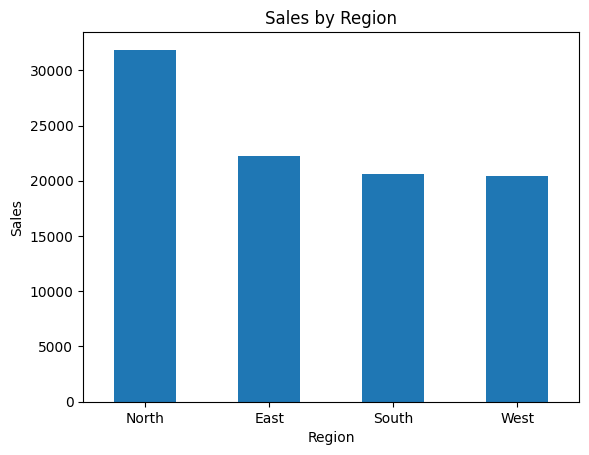

In [20]:
region_sales.plot(kind="bar")
plt.title("Sales by Region")
plt.xlabel("Region")
plt.ylabel("Sales")
plt.xticks(rotation=0)
plt.show()

In [21]:
category_analysis = (
    df.groupby("Category")[["Sales", "Profit"]]
      .sum()
      .sort_values("Sales", ascending=False)
)
category_analysis

,Sales,Profit
Category,,
Electronics,47507.50,15946.73
Furniture,38117.00,12561.18
Clothing,8327.15,2861.69
Office Supplies,1240.40,409.32


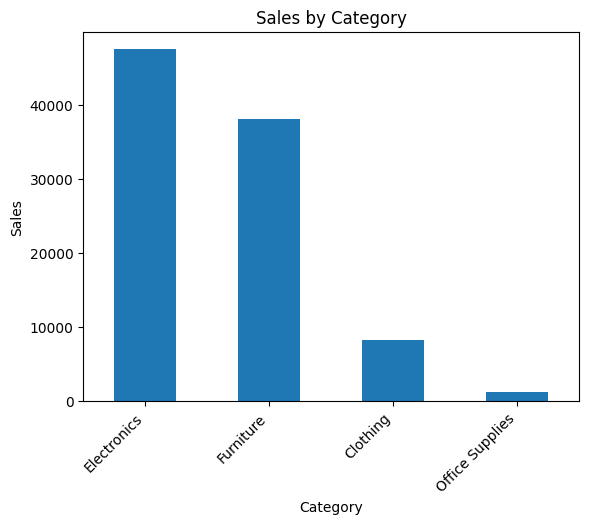

In [22]:
category_analysis["Sales"].plot(kind="bar")
plt.title("Sales by Category")
plt.xlabel("Category")
plt.ylabel("Sales")
plt.xticks(rotation=45, ha="right")
plt.show()

In [23]:
top_products = (
    df.groupby("Product")["Sales"]
      .sum()
      .sort_values(ascending=False)
      .head(10)
)
top_products

Product
Laptop          33065.00
Desk            12012.00
Office Chair    10845.00
Monitor          8954.00
Table            8883.00
Bookshelf        6377.00
Headphones       3895.50
Shoes            3307.50
Backpack         2074.50
Jacket           1901.25
Name: Sales, dtype: float64

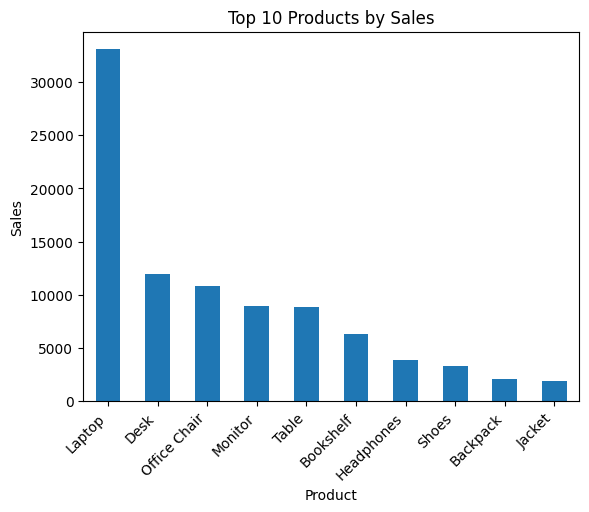

In [24]:
top_products.plot(kind="bar")
plt.title("Top 10 Products by Sales")
plt.xlabel("Product")
plt.ylabel("Sales")
plt.xticks(rotation=45, ha="right")
plt.show()

In [25]:
product_profit = (
    df.groupby("Product")["Profit"]
      .sum()
      .sort_values(ascending=False)
)
product_profit.head(10)

Product
Laptop          11021.46
Desk             4287.92
Office Chair     3297.38
Table            3091.37
Monitor          3012.18
Bookshelf        1884.51
Headphones       1353.68
Shoes            1089.72
Backpack          732.43
Jacket            675.24
Name: Profit, dtype: float64

In [26]:
df["Month"] = df["Order_Date"].dt.to_period("M").astype(str)

monthly_sales = df.groupby("Month")["Sales"].sum()
monthly_sales

Month
2025-01     4630.15
2025-02     4622.60
2025-03     9835.55
2025-04     4369.95
2025-05     4955.45
2025-06     5328.95
2025-07     9517.85
2025-08    11803.85
2025-09    14216.10
2025-10    11297.95
2025-11     8093.20
2025-12     6520.45
Name: Sales, dtype: float64

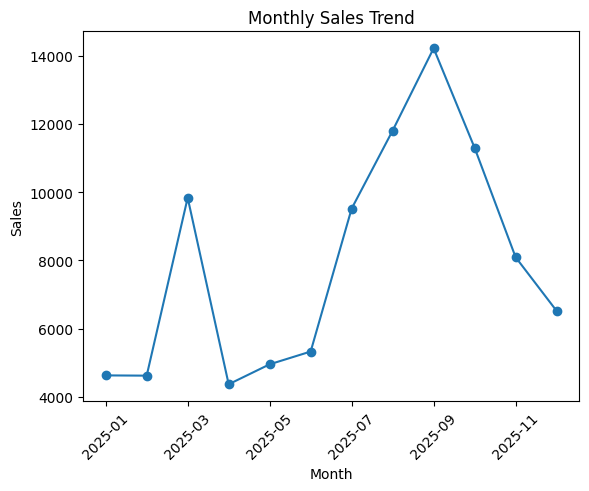

In [27]:
monthly_sales.plot(kind="line", marker="o")
plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Sales")
plt.xticks(rotation=45)
plt.show()

In [28]:
region_sales.idxmax(), region_sales.max()


('North', 31863.2)

In [29]:
df.groupby("Category")["Sales"].sum().idxmax()

'Electronics'

In [30]:
df.groupby("Product")["Sales"].sum().idxmax()


'Laptop'

In [31]:
monthly_sales.idxmax(), monthly_sales.max()

('2025-09', 14216.1)

In [32]:
summary = pd.DataFrame({
    "Metric": [
        "Total Sales",
        "Total Profit",
        "Total Orders",
        "Total Quantity",
        "Profit Margin"
    ],
    "Value": [
        total_sales,
        total_profit,
        total_orders,
        total_quantity,
        profit_margin
    ]
})

summary

,Metric,Value
0,Total Sales,95192.050000
1,Total Profit,31778.920000
2,Total Orders,180.000000
3,Total Quantity,731.000000
4,Profit Margin,33.384006
